# Fase 2 — Desarrollo y Modelado
**Predicción de riesgo de vencimiento de términos legales en tutelas de salud**

Universidad Popular del Cesar · Inteligencia Artificial · 2026-2  
Integrantes: Enor Antonio Acosta Ricardo · Estevan Yesid Sánchez Velasquez

Recorre las fases 04 a 11 del ciclo de vida de ML sobre el dataset del equipo (`dataset_tutelas_salud_sintetico_5000.csv`, 5.000 tutelas, 25 columnas).

In [1]:
import sys, os
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ))
import numpy as np, pandas as pd
from src import fase2_modelado as f2
pd.set_option('display.max_columns', 30)

## 1. Carga del dataset

In [2]:
df_raw = pd.read_csv(f2.DATOS, encoding='utf-8-sig')
print(df_raw.shape)
df_raw.head()

(5000, 25)


,id_tutela,fecha_radicacion,departamento,zona,tipo_entidad_accionada,hecho_principal,nivel_urgencia,complejidad_caso,carga_operativa,grupo_edad,sujeto_especial_proteccion,diagnostico_mencionado,grupo_diagnostico,negacion_previa,numero_adjuntos,solicitudes_previas,plazo_informe_dias,tiempo_respuesta_dias,fecha_respuesta_simulada,margen_dias,porcentaje_plazo_consumido,vencio_termino,nivel_riesgo_real,dias_retraso,fallo_primera_instancia
0,TUT-00001,2024-06-25,Bogota D.C.,Rural,EPS,Medicamento,Baja,Media,Alta,18-39,No,No,No informado,No,6,2,3,2.54,2024-06-27,0.46,0.8467,No,Medio,0.00,Concedida
1,TUT-00002,2024-10-13,Bogota D.C.,Rural,EPS,Demora o negacion explicita,Media,Alta,Media,18-39,No,Si,Sistema nervioso,Si,12,0,3,3.32,2024-10-16,-0.32,1.1067,Si,Vencido,0.32,Negada
2,TUT-00003,2024-05-19,Cesar,Urbana,EPS,Cita con especialista,Media,Media,Baja,40-59,Si,No,No informado,No,4,1,3,1.30,2024-05-20,1.70,0.4333,No,Bajo,0.00,Concedida
3,TUT-00004,2024-06-14,Risaralda,Urbana,EPS,Demora o negacion explicita,Media,Media,Alta,0-17,No,No,No informado,Si,7,2,2,2.25,2024-06-16,-0.25,1.1250,Si,Vencido,0.25,Improcedente
4,TUT-00005,2024-12-25,Antioquia,Urbana,EPS,Cita con especialista,Baja,Media,Media,40-59,No,No,No informado,No,3,0,3,1.74,2024-12-26,1.26,0.5800,No,Bajo,0.00,Concedida


## 2. Limpieza y validación (fase 04)
Nulos, duplicados, tiempos imposibles, consistencia de las columnas calculadas (margen, % de plazo, nivel de riesgo) y valores atípicos.

In [3]:
df = f2.limpiar(df_raw)
f2.bitacora['limpieza']

{'filas': 5000,
 'columnas': 25,
 'nulos': 0,
 'duplicados_exactos': 0,
 'ids_duplicados': 0,
 'tiempos_no_positivos': 0,
 'margen_inconsistente': 0,
 'porcentaje_inconsistente': 0,
 'riesgo_inconsistente': 0,
 'atipicos_1_5_iqr': 113,
 'atipicos_3_iqr': 12,
 'umbral_3_iqr': 4.93,
 'vencidos_entre_atipicos_3_iqr': 12,
 'filas_finales': 5000}

## 3. Ingeniería de características (fase 05)
Codificación ordinal de urgencia, complejidad y carga; binarias Sí/No; variables de fecha; interacción complejidad × carga.

**Excluidas por fuga del objetivo** (se conocen solo después de la respuesta): `fecha_respuesta_simulada`, `margen_dias`, `porcentaje_plazo_consumido`, `vencio_termino`, `nivel_riesgo_real`, `dias_retraso`, `fallo_primera_instancia`.

In [4]:
df = f2.crear_caracteristicas(df)
df[f2.NUM + f2.CAT].head()

,urgencia_ord,complejidad_ord,carga_ord,complejidad_x_carga,plazo_informe_dias,numero_adjuntos,solicitudes_previas,sujeto_especial,diagnostico_si,negacion_previa_si,mes,dia_semana,es_fin_semana,departamento,zona,tipo_entidad_accionada,hecho_principal,grupo_edad,grupo_diagnostico
0,0,1,2,2,3,6,2,0,0,0,6,1,0,Bogota D.C.,Rural,EPS,Medicamento,18-39,No informado
1,1,2,1,2,3,12,0,0,1,1,10,6,1,Bogota D.C.,Rural,EPS,Demora o negacion explicita,18-39,Sistema nervioso
2,1,1,0,0,3,4,1,1,0,0,5,6,1,Cesar,Urbana,EPS,Cita con especialista,40-59,No informado
3,1,1,2,2,2,7,2,0,0,1,6,4,0,Risaralda,Urbana,EPS,Demora o negacion explicita,0-17,No informado
4,0,1,1,1,3,3,0,0,0,0,12,2,0,Antioquia,Urbana,EPS,Cita con especialista,40-59,No informado


## 4. División 70 / 15 / 15 (fase 06), estratificada por nivel de riesgo

In [5]:
train, val, test = f2.dividir(df)
f2.bitacora['particion']

{'train': 3500, 'val': 750, 'test': 750}

In [6]:
X = lambda d: d[f2.NUM + f2.CAT]
Xtr, ytr, Xva, yva, Xte, yte = X(train), train[f2.OBJETIVO], X(val), val[f2.OBJETIVO], X(test), test[f2.OBJETIVO]

## 5. Modelos y ajuste de hiperparámetros (fases 07–09)
M0 Dummy · M1 Regresión lineal (baseline) · M2 Ridge ajustado · M3a/M3b Random Forest · M4 XGBoost ajustado.  
`RandomizedSearchCV`, validación cruzada 5-fold sobre entrenamiento (≈ 1 minuto).

In [7]:
modelos, b_xgb = f2.entrenar_modelos(Xtr, ytr)
f2.bitacora['hiperparametros']

{'Ridge': {'mejores': {'alpha': np.float64(45.7056)},
  'rmse_cv': np.float64(0.5255617922292671),
  'combinaciones': 20},
 'RandomForest': {'mejores': {'n_estimators': 600,
   'min_samples_leaf': 10,
   'max_features': 0.6,
   'max_depth': 12},
  'rmse_cv': np.float64(0.5466114363491523),
  'combinaciones': 25},
 'XGBoost': {'mejores': {'colsample_bytree': np.float64(0.7871),
   'learning_rate': np.float64(0.059),
   'max_depth': 1,
   'min_child_weight': 5,
   'n_estimators': 808,
   'reg_lambda': np.float64(2.6117),
   'subsample': np.float64(0.9074)},
  'rmse_cv': np.float64(0.5275558259501444),
  'combinaciones': 40}}

## 6. Evaluación y comparación (fase 10)

In [8]:
filas = []
for n, m in modelos.items():
    tr, va = f2.metricas(ytr, m.predict(Xtr)), f2.metricas(yva, m.predict(Xva))
    filas.append({'modelo': n, **{f'{k}_train': v for k, v in tr.items()}, **{f'{k}_val': v for k, v in va.items()}})
comp = pd.DataFrame(filas); comp.round(3)

,modelo,MAE_train,RMSE_train,R2_train,MAE_val,RMSE_val,R2_val
0,M0 · Dummy (media),0.543,0.712,0.000,0.549,0.726,-0.000
1,M1 · Regresión lineal (baseline),0.357,0.518,0.471,0.369,0.525,0.478
2,M2 · Ridge (ajustado),0.357,0.518,0.470,0.369,0.524,0.479
3,M3a · Random Forest (por defecto),0.149,0.213,0.911,0.398,0.558,0.409
4,M3b · Random Forest (ajustado),0.336,0.480,0.545,0.385,0.544,0.438
5,M4 · XGBoost (ajustado),0.359,0.519,0.467,0.377,0.533,0.461


In [9]:
cand = comp[~comp.modelo.str.startswith('M0')]
mejor_nombre = cand.loc[cand.RMSE_val.idxmin(), 'modelo']
mejor = modelos[mejor_nombre]; p_te = mejor.predict(Xte)
print('Seleccionado:', mejor_nombre)
for n in ['M1 · Regresión lineal (baseline)', 'M4 · XGBoost (ajustado)', mejor_nombre]:
    print(n, {k: round(v, 3) for k, v in f2.metricas(yte, modelos[n].predict(Xte)).items()})

Seleccionado: M2 · Ridge (ajustado)
M1 · Regresión lineal (baseline) {'MAE': 0.352, 'RMSE': 0.492, 'R2': 0.545}
M4 · XGBoost (ajustado) {'MAE': 0.353, 'RMSE': 0.493, 'R2': 0.543}
M2 · Ridge (ajustado) {'MAE': 0.351, 'RMSE': 0.492, 'R2': 0.545}


## 7. Del tiempo predicho al riesgo y a la alerta (fase 11)
`razón = tiempo predicho ÷ plazo`. Niveles del dataset: Bajo ≤ 0,60 < Medio ≤ 0,85 < Alto ≤ 1,00 < Vencido.  
Alerta estándar: razón > 1,00. Alerta conservadora: razón ≥ 0,95 (umbral elegido en validación para recall ≥ 0,85).

In [10]:
from sklearn.metrics import confusion_matrix, recall_score, precision_score, roc_auc_score
pz = test.plazo_informe_dias.to_numpy(); venc = (yte.to_numpy() / pz) > 1
print('AUC vencimiento:', round(roc_auc_score(venc, p_te / pz), 3))
for u in [1.0001, 0.95]:
    a = (p_te / pz) >= u
    print(f'umbral {u:.2f}: recall {recall_score(venc, a):.2f} · precisión {precision_score(venc, a):.2f} · alertas {a.sum()}')
pd.DataFrame(confusion_matrix(test.nivel_riesgo_real, f2.nivel_riesgo(p_te, pz), labels=f2.NIVELES),
             index=['real '+n for n in f2.NIVELES], columns=['pred '+n for n in f2.NIVELES])

AUC vencimiento: 0.922
umbral 1.00: recall 0.84 · precisión 0.79 · alertas 325
umbral 0.95: recall 0.88 · precisión 0.75 · alertas 357


,pred Bajo,pred Medio,pred Alto,pred Vencido
real Bajo,72,57,8,5
real Medio,20,109,44,24
real Alto,1,38,28,39
real Vencido,2,14,32,257


## 8. Gráficas (generadas por `python src/fase2_modelado.py` en `results/figuras/`)

01_distribucion_objetivo.png


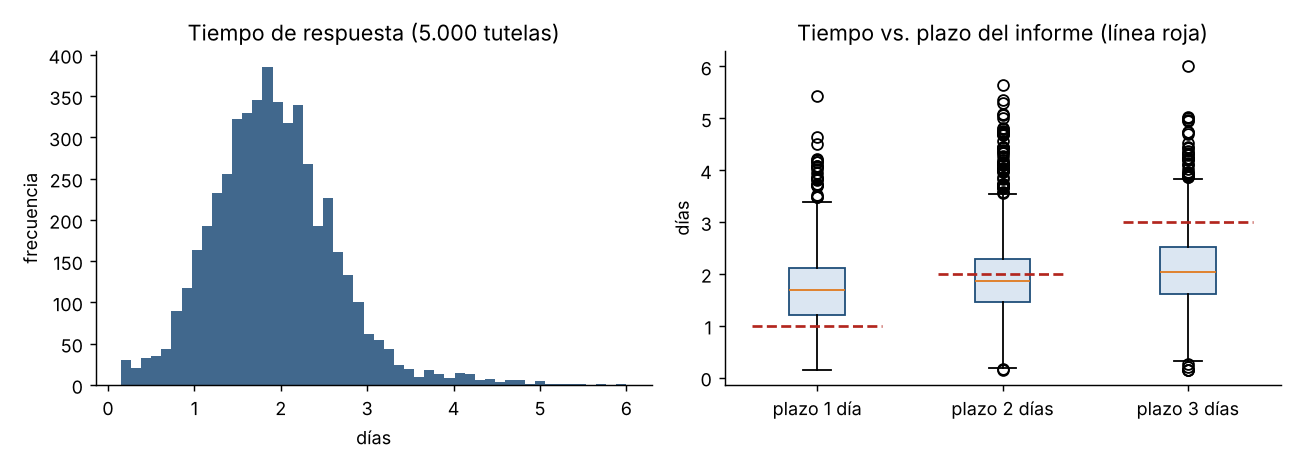

02_comparacion_modelos.png


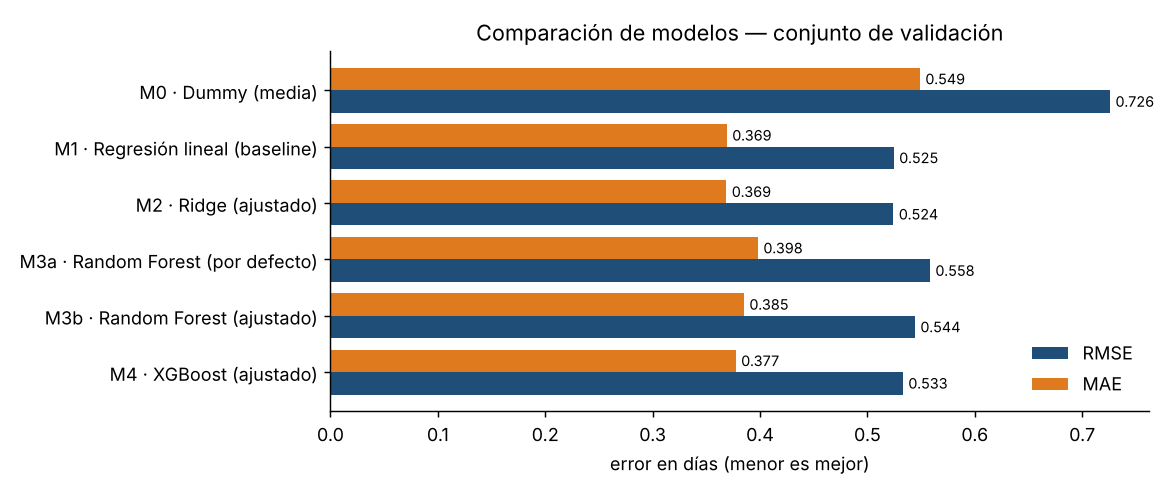

03_real_vs_predicho.png


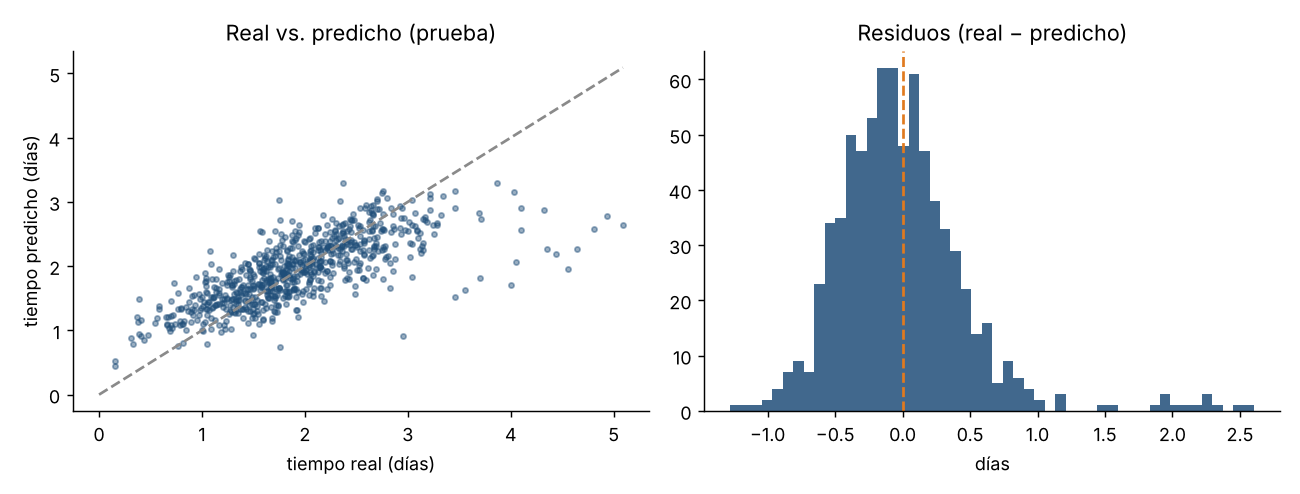

04_importancia_variables.png


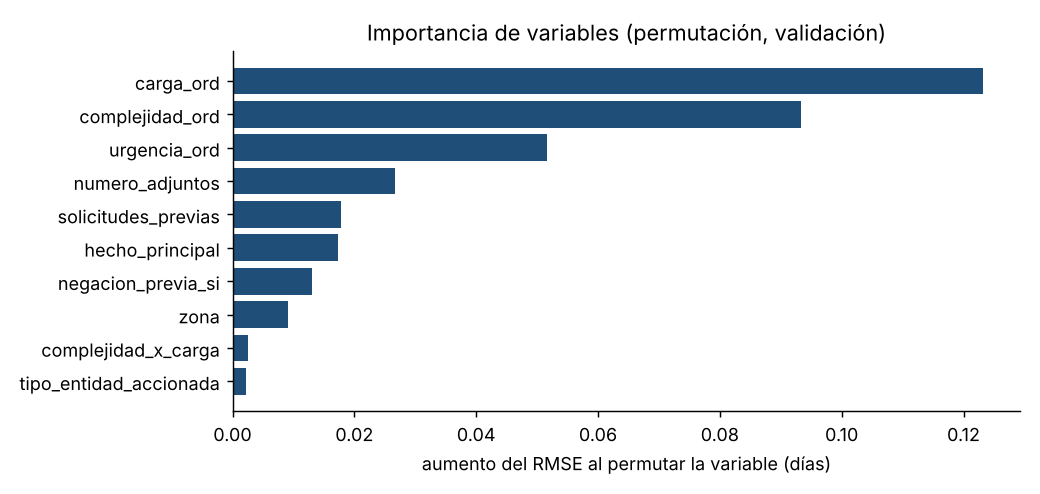

05_curva_umbral.png


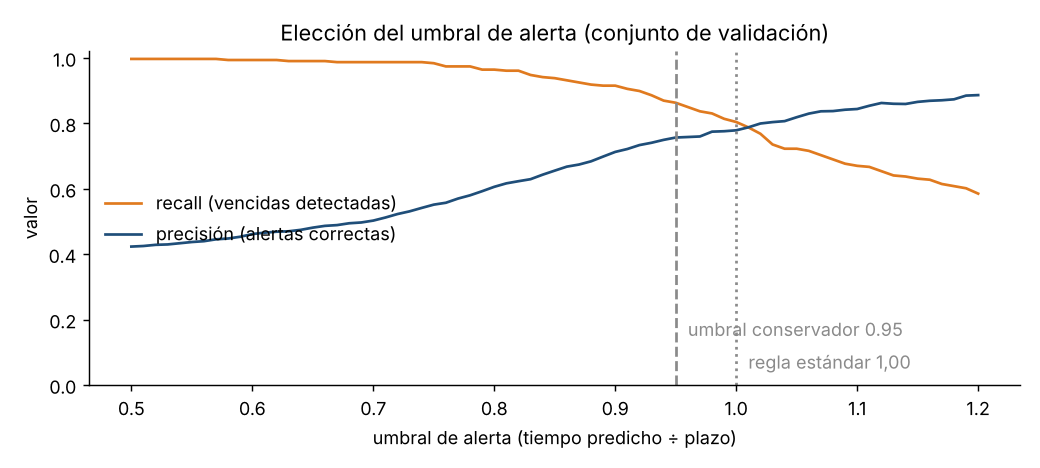

06_train_vs_validacion.png


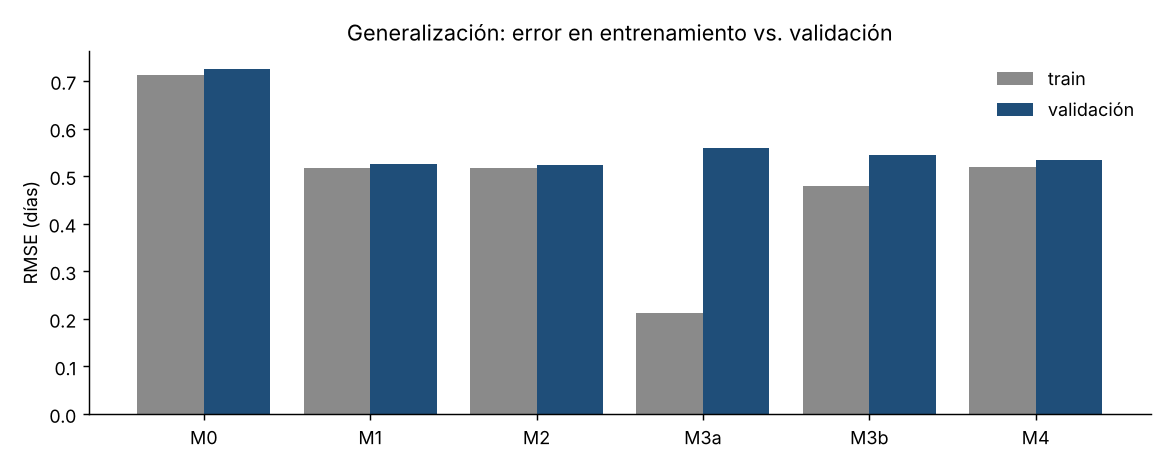

07_xgb_max_depth.png


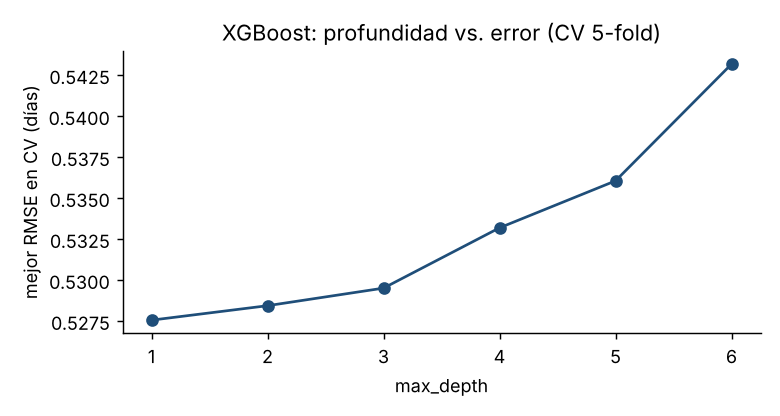

In [11]:
from IPython.display import Image, display
for f in sorted(Path('results/figuras').glob('*.png')):
    print(f.name); display(Image(filename=str(f)))

## 9. Conclusiones preliminares
- Todos los modelos reducen el error del Dummy en ~32 %; R² ≈ 0,48 en validación y 0,55 en prueba.
- Lineal, Ridge y XGBoost empatan: los efectos en estos datos son aditivos (XGBoost elige árboles de profundidad 1).
- Random Forest por defecto sobreajusta (RMSE train 0,21 vs. validación 0,56).
- Se selecciona Ridge: igual de preciso y el más simple de explicar.
- Para el objetivo operativo (anticipar vencimientos) el modelo discrimina bien: AUC 0,92; la regla conservadora detecta 88 % de las tutelas que vencen.